# EDA Sample: Home Court Advantage

**The question:** how much does playing at home actually help, and is it the same for every team?

**The data:** `NBA_merged.csv`, built from the NBA API. Regular-season team box scores, 2014-15 through 2025-26.

**The six questions we ask of any new dataset:**

1. What does one row mean?
2. Is anything missing or broken?
3. What does each variable look like on its own?
4. How do groups or variables compare?
5. Does it change over time?
6. What should we ask next?

EDA is not about proving anything yet. The goal is to learn what the data can and can't tell us before we build on it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Colors used throughout, so "home" always looks the same from chart to chart
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, LIGHT_GRAY = "#0b0b0b", "#c3c2b7"

# Chart style. You only need to set this once per notebook.
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": LIGHT_GRAY, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11, "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)

In [2]:
# If you run this in Colab, upload the file and change this to just "NBA_merged.csv"
DATA_PATH = "../Home Court Advantage/NBA_merged.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)
print(df.shape)  # (rows, columns)

(28878, 68)


## 1. What does one row mean?

Always answer this first. Almost every EDA mistake comes from getting it wrong.

In [3]:
df[["game_id", "game_date", "season", "team_abbr", "opp_abbr",
    "is_home", "true_home", "win", "PTS", "OPP_PTS", "PLUS_MINUS"]].head(4)

,game_id,game_date,season,team_abbr,opp_abbr,is_home,true_home,win,PTS,OPP_PTS,PLUS_MINUS
0,21400001,2014-10-28,2014-15,ORL,NOP,0,0,0,84,101,-17
1,21400001,2014-10-28,2014-15,NOP,ORL,1,1,1,101,84,17
2,21400002,2014-10-28,2014-15,DAL,SAS,0,0,0,100,101,-1
3,21400002,2014-10-28,2014-15,SAS,DAL,1,1,1,101,100,1


In [4]:
# How many rows does each game have?
df.groupby("game_id").size().value_counts()

2    14439
Name: count, dtype: int64

In [5]:
# How many games in each season?
df.groupby("season")["game_id"].nunique()

season
2014-15    1230
2015-16    1230
2016-17    1230
2017-18    1230
2018-19    1230
2019-20    1059
2020-21    1080
2021-22    1230
2022-23    1230
2023-24    1230
2024-25    1230
2025-26    1230
Name: game_id, dtype: int64

**What to notice**

- Every game appears **twice**, once from each team's side. One row is one team in one game.
- Most seasons have 1,230 games. 2019-20 and 2020-21 are shorter because of COVID. Totals from those seasons aren't comparable to the others, but averages are.

## 2. Is anything missing or broken?

In [6]:
missing = df.isna().sum()
missing[missing > 0]

FT_PCT          1
arena_state    36
dtype: int64

In [7]:
# Why is FT_PCT blank in one row?
df.loc[df["FT_PCT"].isna(), ["game_date", "team_abbr", "FTM", "FTA", "FT_PCT"]]

,game_date,team_abbr,FTM,FTA,FT_PCT
23852,2024-04-09,BOS,0,0,NaN


In [8]:
# Why is arena_state blank?
df.loc[df["arena_state"].isna(), "arena_city"].value_counts()

arena_city
Mexico City, Mexico    22
London                 12
Berlin                  2
Name: count, dtype: int64

In [9]:
# Duplicates, and does the margin match the score?
print("Duplicate team-games:", df.duplicated(["game_id", "team_abbr"]).sum())
print("Margin doesn't match score:", (df["PLUS_MINUS"] != df["PTS"] - df["OPP_PTS"]).sum())

Duplicate team-games: 0
Margin doesn't match score: 0


In [10]:
df[["win", "PLUS_MINUS", "PTS"]].describe().round(2)

,win,PLUS_MINUS,PTS
count,28878.0,28878.00,28878.00
mean,0.5,0.00,109.84
std,0.5,14.76,13.30
min,0.0,-73.00,64.00
25%,0.0,-10.00,101.00
50%,0.5,0.00,110.00
75%,1.0,10.00,119.00
max,1.0,73.00,176.00


**What to notice**

- **Blank cells usually have a reason.** Boston took zero free throws in one game, so a percentage can't be calculated. The blank states are games in Mexico City, London and Berlin. Neither is an error, so we shouldn't fill them in.
- **The trap:** average `win` is exactly 0.50 and average `PLUS_MINUS` is exactly 0. That isn't a finding. Every game has one winner and one loser in the file, so the two sides always cancel out.

To study home court, we need to count each game once, from the home team's side. Before filtering, let's check what the home flags really mean.

In [11]:
pd.crosstab(df["is_home"], df["true_home"])

true_home,0,1
is_home,,
0,14449,0
1,88,14341


In [12]:
# Games flagged as a true home game that were played outside the U.S. and Canada
abroad = df[(df["true_home"] == 1) & df["arena_state"].isna()]
print("Flagged as true home, but played abroad:", len(abroad))
abroad[["game_date", "team_abbr", "opp_abbr", "arena_city"]].head(4)

Flagged as true home, but played abroad: 16


,game_date,team_abbr,opp_abbr,arena_city
233,2014-11-12,MIN,HOU,"Mexico City, Mexico"
1169,2015-01-15,MIL,NYK,London
3023,2015-12-03,SAC,BOS,"Mexico City, Mexico"
3635,2016-01-14,ORL,TOR,London


**What to notice**

- `is_home` has 88 rows where `true_home` is 0. Those are the 2020 Orlando bubble games, where the "home" team had no real home court.
- **`true_home` has a labeling gap.** 16 games in Mexico City and London are still marked as true home games. The 2024-25 and later international games are correctly marked neutral, so the rule changed partway through the data. **Worth fixing in the merge step.**

Here we keep real home games only, and build a matching table for the visiting teams.

In [13]:
home = df[(df["true_home"] == 1) & df["arena_state"].notna()].copy()
away = df[(df["is_home"] == 0) & df["game_id"].isin(home["game_id"])].copy()

print("Home rows:", len(home), "| Unique games:", home["game_id"].nunique())
print("Home win rate:", round(home["win"].mean(), 3))
print("Average home margin:", round(home["PLUS_MINUS"].mean(), 2))

Home rows: 14325 | Unique games: 14325
Home win rate: 0.566
Average home margin: 2.18


## 3. What does one variable look like?

A histogram shows the whole shape, which a single average can't.

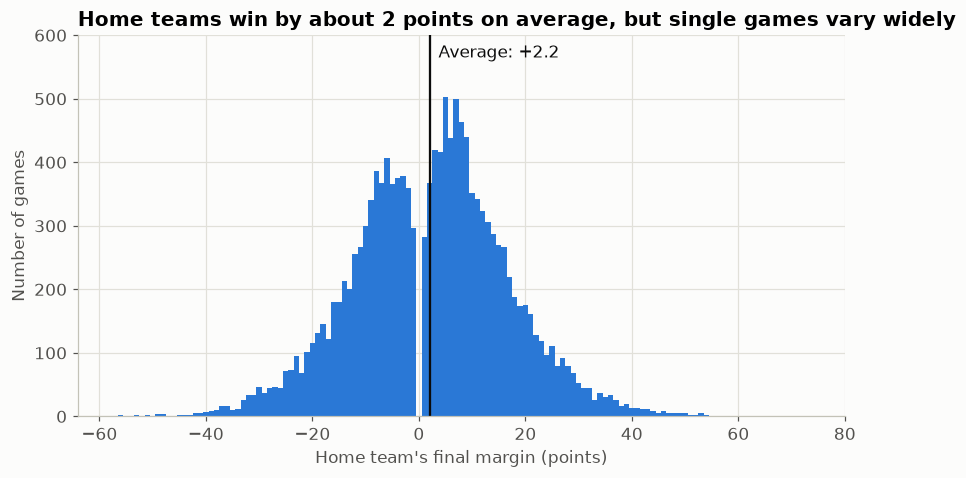

Standard deviation: 14.6
Games decided by exactly 0 points: 0


In [14]:
margin = home["PLUS_MINUS"]
bins = np.arange(margin.min() - 0.5, margin.max() + 1.5, 1)

fig, ax = plt.subplots()
ax.hist(margin, bins=bins, color=BLUE)
ax.axvline(margin.mean(), color=INK, linewidth=1.5)
ax.set_ylim(0, 600)
ax.text(margin.mean() + 1.5, 565, f"Average: {margin.mean():+.1f}", color=INK)
ax.set_title("Home teams win by about 2 points on average, but single games vary widely")
ax.set_xlabel("Home team's final margin (points)")
ax.set_ylabel("Number of games")
plt.show()

print("Standard deviation:", round(margin.std(), 1))
print("Games decided by exactly 0 points:", (margin == 0).sum())

**What to notice**

- The curve is roughly bell-shaped and centered a little above zero.
- The gap in the middle is real. Basketball has no ties, so a margin of 0 never happens.
- The spread (about 15 points) is roughly seven times the average edge (about 2 points). Home court is real, but it's small next to everything else that happens in a game.

## 4. How do groups compare?

A box plot compares groups by showing the middle, the spread and the extremes all at once.

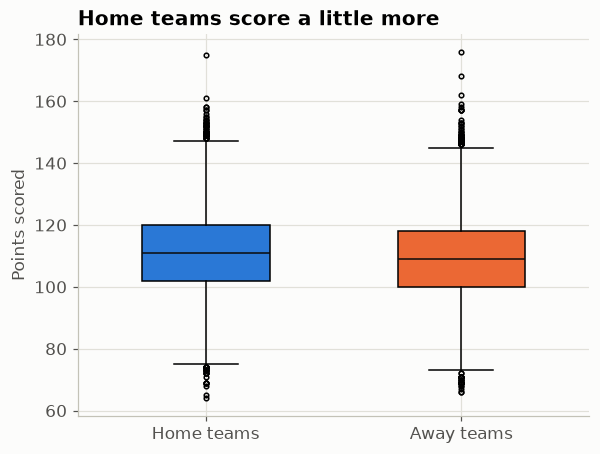

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
box = ax.boxplot([home["PTS"], away["PTS"]], patch_artist=True, widths=0.5,
                 medianprops={"color": INK}, flierprops={"markersize": 3})
box["boxes"][0].set_facecolor(BLUE)
box["boxes"][1].set_facecolor(ORANGE)
ax.set_xticks([1, 2], ["Home teams", "Away teams"])
ax.set_ylabel("Points scored")
ax.set_title("Home teams score a little more")
plt.show()

In [16]:
# Where does the home edge come from?
stats = ["PTS", "efg_pct", "FG3_PCT", "REB", "AST", "TOV", "PF", "FTA"]

comparison = pd.DataFrame({"Home": home[stats].mean(), "Away": away[stats].mean()})
comparison["Home minus Away"] = comparison["Home"] - comparison["Away"]
comparison.round(3)

,Home,Away,Home minus Away
PTS,110.899,108.719,2.180
efg_pct,0.534,0.524,0.010
FG3_PCT,0.362,0.353,0.008
REB,44.402,43.510,0.892
AST,24.936,24.040,0.896
TOV,14.087,14.181,-0.094
PF,19.606,20.011,-0.405
FTA,22.896,22.279,0.618


**What to notice**

- The two boxes overlap almost completely. That's what a real but small difference looks like.
- The table points to small edges everywhere: home teams shoot better, rebound more, assist more and foul less. No single stat explains it, so that's a good next question.

### Does the advantage differ by team?

The obvious approach is to rank teams by home margin. But that mostly tells us who was good. A better measure compares each team to itself: **home margin minus away margin**.

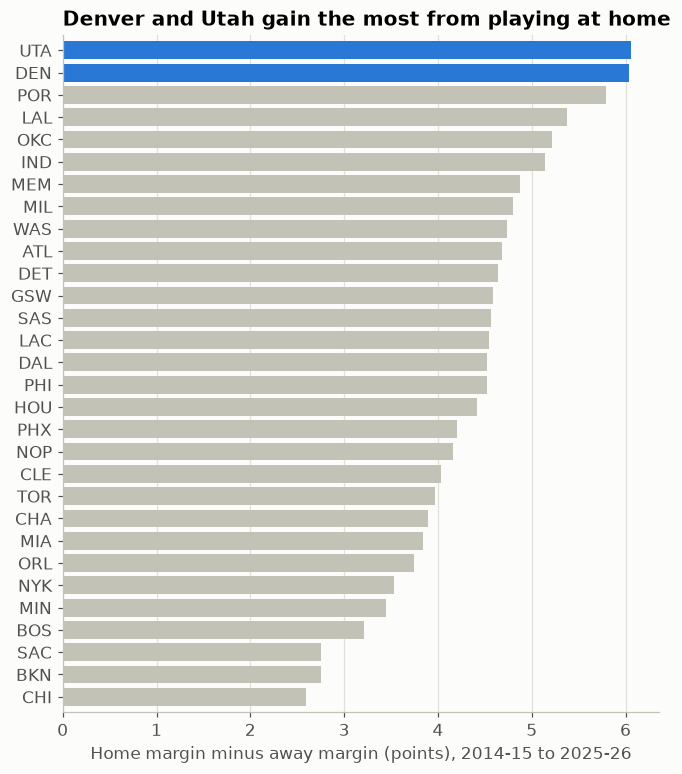

Best average HOME margin: BOS 6.9
Boston's rank by home-minus-away edge: 27 of 30


In [17]:
home_margin = home.groupby("team_abbr")["PLUS_MINUS"].mean()
away_margin = away.groupby("team_abbr")["PLUS_MINUS"].mean()
team_edge = (home_margin - away_margin).sort_values()

colors = [BLUE if team in team_edge.index[-2:] else LIGHT_GRAY for team in team_edge.index]

fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(team_edge.index, team_edge.values, color=colors)
ax.set_title("Denver and Utah gain the most from playing at home")
ax.set_xlabel("Home margin minus away margin (points), 2014-15 to 2025-26")
ax.grid(axis="y", visible=False)
ax.margins(y=0.01)
plt.show()

print("Best average HOME margin:", home_margin.idxmax(), round(home_margin.max(), 1))
print("Boston's rank by home-minus-away edge:", int(team_edge.rank(ascending=False)["BOS"]), "of 30")

**What to notice**

- Boston has the best home margin in the data, but ranks near the bottom on this measure. Boston was simply good everywhere. **How you define a metric can reverse the story.**
- Denver and Utah top the list, and both play at high altitude. That's a hypothesis worth testing, not a conclusion yet.
- Each team's number carries uncertainty of about 1 point, so the teams in the middle of the chart aren't meaningfully different from each other.

### Which game stats move with the margin?

A scatter plot and a correlation (r) show how two numeric variables relate. r runs from -1 to +1.

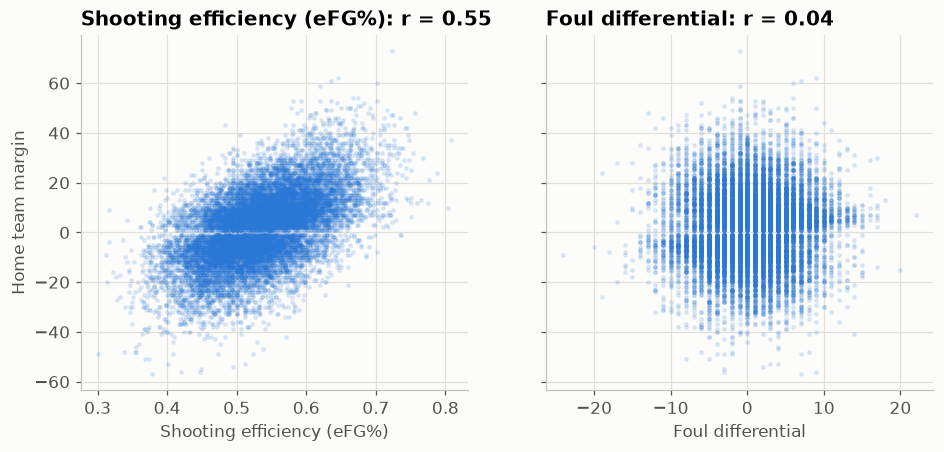

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)

for ax, col, label in zip(axes, ["efg_pct", "foul_diff"], ["Shooting efficiency (eFG%)", "Foul differential"]):
    r = home[col].corr(home["PLUS_MINUS"])
    ax.scatter(home[col], home["PLUS_MINUS"], s=5, alpha=0.12, color=BLUE)
    ax.set_title(f"{label}: r = {r:.2f}")
    ax.set_xlabel(label)

axes[0].set_ylabel("Home team margin")
plt.show()

**What to notice**

- Left: a clear upward cloud. Teams that shoot better win by more, which is not surprising.
- Right: almost no pattern. Across all games, fouls barely track the final margin.
- Careful: correlation is not cause, and part of the left panel is close to automatic, since points come from made shots.

## 5. Does it change over time?

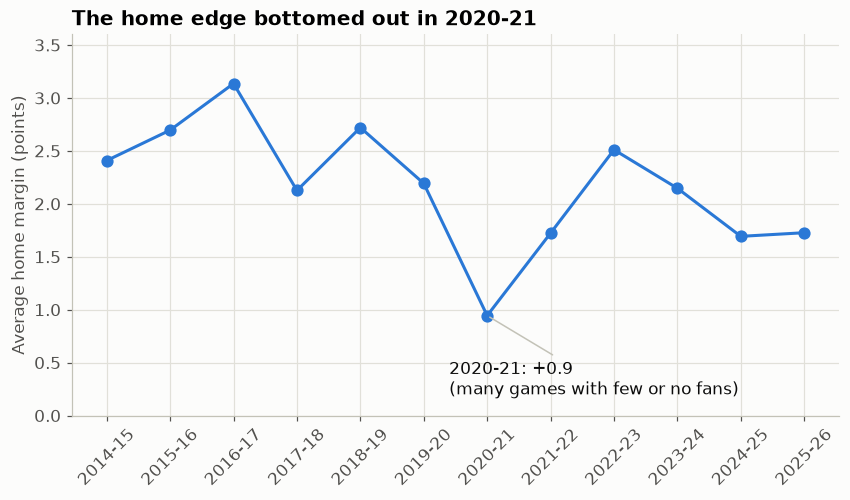

season
2014-15    2.41
2015-16    2.70
2016-17    3.14
2017-18    2.13
2018-19    2.72
2019-20    2.19
2020-21    0.94
2021-22    1.72
2022-23    2.51
2023-24    2.15
2024-25    1.69
2025-26    1.73
Name: PLUS_MINUS, dtype: float64

In [19]:
by_season = home.groupby("season")["PLUS_MINUS"].mean()

fig, ax = plt.subplots()
ax.plot(by_season.index, by_season.values, color=BLUE, marker="o", markersize=7)
ax.annotate(f"2020-21: {by_season['2020-21']:+.1f}\n(many games with few or no fans)",
            xy=("2020-21", by_season["2020-21"]), xytext=(5.4, 0.2), color=INK,
            arrowprops={"arrowstyle": "-", "color": LIGHT_GRAY})
ax.set_ylim(0, 3.6)
ax.set_title("The home edge bottomed out in 2020-21")
ax.set_ylabel("Average home margin (points)")
ax.tick_params(axis="x", rotation=45)
plt.show()

by_season.round(2)

**What to notice**

- The dip in 2020-21 is what we'd expect if crowds matter, and it makes a natural comparison for the project.
- The edge recovered in 2022-23 but has been lower in the last two seasons than it was in the late 2010s.
- One season is a small sample of a noisy measure, so treat this as a lead, not proof.

## 6. What should we ask next?

**What we learned**

- Home teams win about 57% of games and by about 2 points, but the game-to-game spread is much larger.
- The data needs care: each game has two rows, and 16 international games are mislabeled as true home games.
- Comparing a team to itself tells a different story than a plain ranking.

**Your turn**

1. Join `Arena_Attendance_per_Season.csv`. Do fuller arenas have a bigger edge? Watch out: that file labels a season by its ending year (2026), while this one uses "2025-26".
2. Is Denver and Utah's edge steady every year, or driven by a few seasons?
3. Do fouls or free throws favor home teams more in close games?